In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from itertools import permutations
from math import factorial

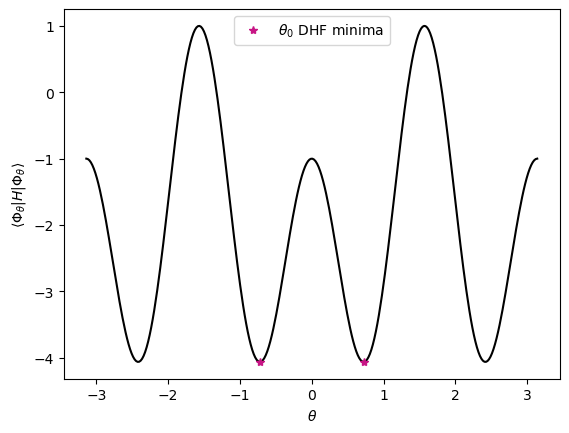

In [3]:
def exH(th,eps,chi,P):
    V = -chi*eps/(P-1)
    exH = -eps*P/2+eps*P*np.sin(th)**2+V*P*(P-1)*(np.sin(th)*np.cos(th))**2
    return exH

eps = 1
P = 2
chi = 8
V = -chi*eps/(P-1)
a_dhf = 0.5*np.arccos(1.0/chi)

th = np.linspace(-np.pi,np.pi,300)
plt.plot(th,exH(th,eps,chi,P),'k')
plt.plot(a_dhf,exH(a_dhf,eps,chi,P),'*',color='mediumvioletred',label=r'$\theta_0$ DHF minima')
plt.plot(-a_dhf,exH(-a_dhf,eps,chi,P),'*',color='mediumvioletred')
plt.ylabel(r'$\langle \Phi_\theta | H | \Phi_\theta \rangle$')
plt.xlabel(r'$\theta$')
plt.legend()
# plt.savefig(f'C:/Users/annas/Documents/2026/Honours/Thesis/Figures/TDDM_figures/tddm_exH_N{P}_chi{chi}_V{-chi*eps/(P-1)}.eps',bbox_inches='tight',dpi=300)
plt.show()


In [ ]:

def Hh0(P,eps):
    sign = np.concatenate([-np.ones(P), np.ones(P)])
    h0base = np.diag(eps/2 * sign).astype(complex)
    IX = np.eye(2*P,dtype=complex)
    h0full = np.zeros(((2*P)**P,(2*P)**P),dtype=complex)
    for p in range(P):
        # want to sum over the p 1body hamiltonians
        elements = [h0base if i==p else IX for i in range(P)]

        # build the kronecker producted form for the pth 1body hamiltonian
        h0 = elements[0]
        for element in elements[1:]:
            h0 = np.kron(h0,element)
        h0full += h0
    return h0full

lo = lambda j: j        # level -(j+1),  j = 0..P-1
up = lambda j: P + j    # level +(j+1)

def Hv():
    """Bare <ab|v|a'b'> in Tohyama's convention (H_int = 1/2 sum v a+a+aa)."""
    vbase = np.zeros((2*P,)*4, dtype=complex)
    for j in range(P):
        for k in range(P):
            vbase[up(j), up(k), lo(j), lo(k)] = V   # (V/2) J_+^2
            vbase[lo(j), lo(k), up(j), up(k)] = V   # (V/2) J_-^2
    return vbase

def Ham():
    return Hh0()+Hv()


H = Ham()
print(H.shape)

def slat(th):
    phi = np.zeros((2*P),dtype=complex)
    c, s = np.cos(th), np.sin(th)
    for j in range(P):
        phi[lo(j)] = c
        phi[up(j)] = s
    slat = phi
    for i in range(P-1):
        slat = np.kron(slat,phi)
    return slat

slater = slat(0)
print(slater.shape)
print(Hh0().shape)

(4, 4, 4, 4)
(16,)
(4, 4)


In [71]:
def orbitals(th, P):
    """The P occupied DHF orbitals as columns of a (2P, P) matrix.
    Orbital p = cos(th)|lo(p)> + sin(th)|up(p)>  -- each in its OWN (lo,up) pair,
    so they are orthonormal for any th.  th = alpha, matching n_DHF."""
    A = np.zeros((2*P, P), dtype=complex)
    for p in range(P):
        A[p, p]   = np.cos(th)     # lo(p)
        A[P+p, p] = np.sin(th)     # up(p)
    return A

def h0_1body(P, eps):
    return np.diag(eps/2*np.concatenate([-np.ones(P), np.ones(P)])).astype(complex)

def v_2body(P, V):
    """Bare <ab|v|a'b'>, Tohyama convention (H_int = 1/2 sum v a+ a+ a a)."""
    v = np.zeros((2*P,)*4, dtype=complex)
    for j in range(P):
        for k in range(P):
            v[P+j, P+k, j, k] = V
            v[j, k, P+j, P+k] = V
    return v

def braket_lowdin(th1, th2, P, eps, chi):
    """<Slat(th1)|H|Slat(th2)>, and the overlap <Slat(th1)|Slat(th2)>."""
    V = -chi*eps/(P-1)
    h0, v4 = h0_1body(P, eps), v_2body(P, V)
    A, B = orbitals(th1, P), orbitals(th2, P)
    S    = A.conj().T @ B                      # P x P orbital overlap
    ovlp = np.linalg.det(S)
    rho  = B @ np.linalg.inv(S) @ A.conj().T   # transition density: <1|a+_c a_a|2>/<1|2>
    rho2 = (np.einsum('ac,bd->abcd', rho, rho)
            - np.einsum('ad,bc->abcd', rho, rho))
    E = np.einsum('ij,ji->', rho, h0) + 0.5*np.einsum('ijkl,klij->', rho2, v4)
    t=np.einsum('ij,ji->', rho, h0)
    return ovlp*E, ovlp



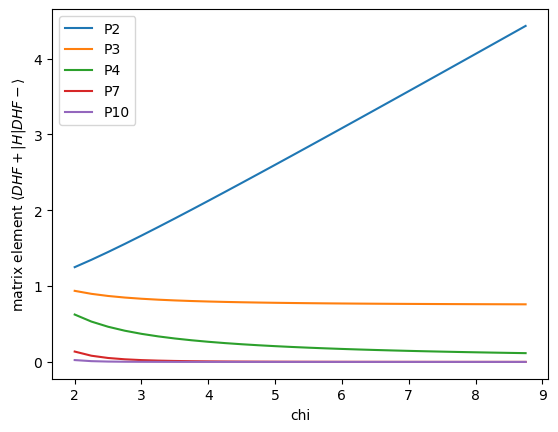

In [75]:
eps = 1
P_list = [2,3,4,7,10]
chi_list = np.arange(2,9,0.25)

for P in P_list:
    E_list=[]
    delEs=[]
    for chi in chi_list:
        th1, th2 = 0.5*np.arccos(1/chi), -0.5*np.arccos(1/chi)
        E, ovlp = braket_lowdin(th1, th2, P, eps, chi)
        E_list.append(E)
    E_list=np.array(E_list)
    plt.plot(chi_list,np.abs(E_list),label=f'P{P}')
plt.legend()
plt.ylabel(r'matrix element $\langle DHF+|H|DHF-\rangle$')
plt.xlabel('chi')
plt.show()

        

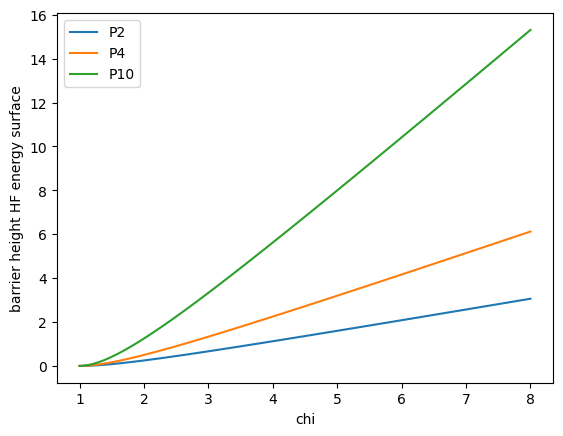

In [62]:
chis=np.linspace(1,8,100)
def delE(chi,P):
    return P*eps/(4*chi)*(chi-1)**2

P=2
delEs = [delE(chi,P) for chi in chis]
plt.plot(chis,delEs,label=f'P{P}')

P=4
delEs = [delE(chi,P) for chi in chis]
plt.plot(chis,delEs,label=f'P{P}')

P=10
delEs = [delE(chi,P) for chi in chis]
plt.plot(chis,delEs,label=f'P{P}')
plt.legend()
plt.xlabel('chi')
plt.ylabel('barrier height HF energy surface')
plt.show()

c:\Users\annas\anaconda3\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\annas\anaconda3\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


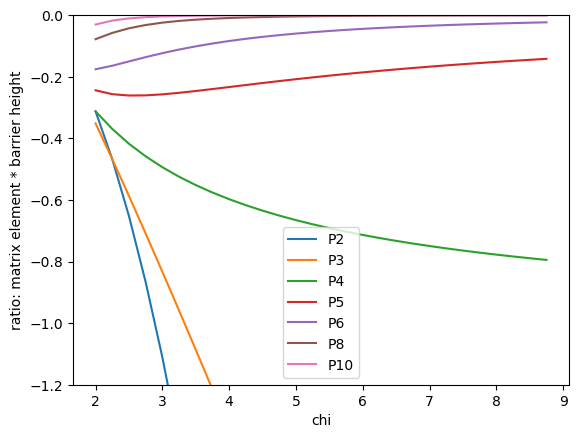

In [68]:
P_list = [2,3,4,5,6,8,10]
chi_list = np.arange(2,9,0.25)

for P in P_list:
    E_list=[]
    delEs=[]
    for chi in chi_list:
        th1, th2 = 0.5*np.arccos(1/chi), -0.5*np.arccos(1/chi)
        E, ovlp = braket_lowdin(th1, th2, P, eps, chi)
        E_list.append(E)
        delEs.append(delE(chi,P))
    E_list=np.array(E_list)
    delEs=np.array(delEs)
    plt.plot(chi_list,E_list*delEs,label=f'P{P}')
plt.legend()
plt.ylabel(r'ratio: matrix element * barrier height')
plt.xlabel('chi')
plt.ylim(-1.2,0)
plt.show()

In [ ]:
P_list = [2,3,4,5,6,8,10]
chi_list = np.arange(2,9,0.25)

for P in P_list:
    E_list=[]
    delEs=[]
    for chi in chi_list: